In [1]:
import sys
sys.path.insert(0,'/Users/martincaroe/Desktop/MARTIN/Copenhagen Business School/Msc Economics and Business Administration - Finance and Investments /3 Semester/Python for the Financial Economics/Fork/python_for_the_financial_economist')


"""
Magic commands
"""

%load_ext autoreload
%autoreload 2

"""
Load relevant packages
"""

import numpy as np
import pandas as pd

# plotting
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import animation, cm
import seaborn as sns

# working with time
import datetime
from scipy import stats
from scipy import optimize

# pandas data reader for downloading data
from pandas_datareader.data import DataReader
from pandas_datareader.famafrench import FamaFrenchReader, get_available_datasets

# for typehints
from typing import Union, List

# cvxopt and cvxpy for optimization
import cvxopt
import cvxpy as cp

"""
Own packages
"""

# nominal yield curve data
from codelib.dal.fred_yield_data import get_nominal_yield_data

# moments: kurtosis with probs, etc.
from codelib.statistics import moments as mom

# functions for calculating risk budget and portfolio risk metrics
from codelib.portfolio_optimization import risk_budget as rb
from codelib.portfolio_optimization import risk_metrics as rm

from codelib.visualization.base import correlation_plot, risk_waterfall_chart, waterfall_chart

# Default plotting layout
from codelib.visualization.layout import DefaultStyle
DefaultStyle();

# Exercises - Week 5

In this week we will look at a few exercises involving minimization and maximization.


## Problem 1: Second order conditions

In this problem, we will look at the [second derivative test](https://en.wikipedia.org/wiki/Second_partial_derivative_test) for determining whether a critical point is a local minimum or maximum.

Consider the function

$$
f(x,y,z) = -x^2 - y^2 - z^2
$$

__Question 1__

What are the first order partial derivatives? Find the stationary/critical point. Also maximize the function using `scipy.optimize.minimize`.

__Question 2__

What are the second order partial derivatives? Write up the Hessian.

__Question 3__

The properties of the Hessian matrix are important for determining whether the critical point / stationary point is a maximum, minimum or neither of the two.

* If the Hessian is negative definite, then the stationary point is a local maximum
* If the Hessian is positive definite, then the stationary point is a local minimum
* If the Hessian is indefinite, then the stationary point is a a saddle point

Otherwise, the test is inconclusive.

We need to remember that a [definite matrix](https://en.wikipedia.org/wiki/Definite_matrix) can be defined in the following way. A  symmetric matrix, $\mathbf{A}$, is said to be positive definite if for every vector $\mathbf{v} \neq \mathbf{0}$

$$
\mathbf{v}^\top  \mathbf{A} \mathbf{v} > 0
$$

and negative definite if

$$
\mathbf{v}^\top  \mathbf{A} \mathbf{v} < 0
$$
For semi-definiteness replace $>$ and $<$ with respectively $\geq$ and $\leq$.


Is the matrix negative definite?

__Question 4__

For a symmetric, positive definite matrix then the above definition will be equivalnt to all the eigenvalues being positive. For a negative definite matrix then all the eigenvalues will be negative.

Find the eigenvalues (use e.g. `numpy.linalg.eigvals`).

__Question 5__

Will the stationary point be a minimum or maximum?

__Question 6__

Assume now that $f(x,y,z) = -x^2 + y^2 - z^2$. Will this function also have a maximum at $(x,y,z) = (0, 0, 0)$?

__Question 7__

Define a function that checks if a symmetric matrix is negative definite.



### Solution

__Question 1__

The first order partial derivatives are given by

\begin{eqnarray}
f_x^\prime(x,y,z) &=& -2x \nonumber \\
f_y^\prime(x,y,z) &=& -2y \nonumber  \\
f_z^\prime(x,y,z) &=& -2z \nonumber
\end{eqnarray}

The only solution to the three equations obtained by setting the partial derivatives equal to zero is $(x, y, z) = (0,0,0)$



In [2]:
func_prob1 = lambda x: -x[0]**2 - x[1]**2 - x[2]**2

# remember that we want to maximize
res = optimize.minimize(lambda x: -func_prob1(x), [1,2,-1])
res

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 3.2847621978269763e-15
        x: [-4.673e-08 -2.118e-08 -2.555e-08]
      nit: 2
      jac: [-7.855e-08 -2.745e-08 -3.620e-08]
 hess_inv: [[ 9.167e-01 -1.667e-01  8.333e-02]
            [-1.667e-01  6.667e-01  1.667e-01]
            [ 8.333e-02  1.667e-01  9.167e-01]]
     nfev: 12
     njev: 3

__Question 2__

The second order partial derivatives are given by

\begin{eqnarray}
f_{xx}^{\prime\prime}(x,y,z) &=& -2 \nonumber \\
f_{yy}^{\prime\prime}(x,y,z) &=& -2 \nonumber  \\
f_{zz}^{\prime\prime}(x,y,z) &=& -2 \nonumber \\
f_{xy}^{\prime\prime}(x,y,z) &=& 0 \nonumber \\
f_{xz}^{\prime\prime}(x,y,z) &=& 0 \nonumber \\
f_{yz}^{\prime\prime}(x,y,z) &=& 0 \nonumber \\
\end{eqnarray}

The Hessian is therefore
$$
H(x,y,z) = \begin{bmatrix}
-2 & 0 & 0 \\
0 & -2 & 0 \\
0 & 0 & -2
\end{bmatrix}
$$

__Question 3__


If the Hessian matrix is negative definite, then the quadratic form

$$
\mathbf{v}^\top \mathbf{H} \mathbf{v} = -2v_1^2 - 2v_2^2 -2 v_3^2
$$

should be negative for all $\mathbf{v} \neq \mathbf{0}$. Since $v_1^2, v_2^2, v_3^2$ always will be positive, then the quadratic form will always be negative.

__Question 4__

The eigenvalues will solve

$$
\det \left(\mathbf{H} - \lambda \mathbf{I} \right) = \det \begin{bmatrix}
-2 - \lambda & 0 & 0 \\
0 & -2  - \lambda & 0 \\
0 & 0 & -2 - \lambda
\end{bmatrix} = (-2 - \lambda)(-2 - \lambda)(-2 - \lambda) = 0
$$

Thus, all eigenvalues must be equal to $\lambda = -2$.

This is in agreement with the results from the previous problem. Having all negative eigenvalues corresponds to the matrix under consideration being negative definite.

In [3]:
hess_mat = np.diag(np.ones(3) * -2)

np.linalg.eigvals(hess_mat)

array([-2.+0.j, -2.+0.j, -2.+0.j])

__Question 5__

The stationary point will be a (global) maximum since the Hessian is negative definite

__Question 6__

Again, we will have

$$
\begin{eqnarray}
f_x^\prime(x,y,z) &=& -2x \nonumber \\
f_y^\prime(x,y,z) &=& 2y \nonumber  \\
f_z^\prime(x,y,z) &=& -2z
\end{eqnarray}
$$

with a stationary point at $(x,y,z) = (0, 0, 0)$.

The Hessian is
$$
H(x,y,z) = \begin{bmatrix}
-2 & 0 & 0 \\
0 & 2 & 0 \\
0 & 0 & -2
\end{bmatrix}
$$

which will have two eigenvalues equal to $-2$ and one eigenvalue equal to $2$. The Hessian will therefore be indefinite and the stationary point will be a saddle point.

In [4]:
hess_new_mat = np.diag([-2, 2, -2])

np.linalg.eigvals(hess_new_mat)

array([-2.+0.j,  2.+0.j, -2.+0.j])

__Question 7__

In [5]:
def is_neg_def(matrix: np.array) -> bool:
    return np.all(np.linalg.eigvals(matrix) < 0)

In [6]:
is_neg_def(hess_mat)

np.True_

In [7]:
is_neg_def(hess_new_mat)

np.False_

**Tolkning (Q1-Q5):** The only flat point of f is (0,0,0), and the numerical optimizer finds the same point. The Hessian is −2 on the diagonal, so the surface curves DOWN in every direction (like the top of a hill), which is confirmed by all three eigenvalues being negative (−2). A negative definite Hessian means the flat point is a maximum.

**Tolkning (Q6-Q7):** Changing the sign of the y² term makes the surface curve UP along y but DOWN along x and z, like a horse saddle. The Hessian now has both negative and positive eigenvalues (indefinite), so (0,0,0) is a saddle point, not a maximum. The small function is_neg_def turns this test into code: it returns True only if ALL eigenvalues are negative (this works for symmetric matrices such as a Hessian).

## Problem 2: Minimizing distance

Assume that Luke Skywalker is currently located at the point $A=(x,y,z)=(5, 5, 5)$ in his X-Wing Starfighter. He needs to gather critical information on the planet Endor before joining the rebel forces at the point $B=(x,y,z) = (6, 6, 6)$. The planet Endor is defined by the 3D ball

$$
x^2 + y^2 + z^2 = 1
$$

__Question 1__

What is the formula for the distance between the point $A$ and a arbitrary point on the surface of the planet $C$ and back to the point $B$? ([euclidian distance](https://en.wikipedia.org/wiki/Euclidean_distance) or [euclidian norm](https://en.wikipedia.org/wiki/Norm_(mathematics)))

__Question 2__


What is the total distance when $C = (1, 0, 0)$?

__Quesiton 3__

We want to help Luke Skywalker to find the optimal place on Endor to retrieve the information. Set up the constrained minimization problem that Luke Skywalker is facing.

__Quesiton 4__

Solve the constrained minimization problem numerically.



### Solution

__Question 1__

Define $C=(x,y,z)$ to be an abitrary point on the planet. Then, we calcuclate the distance between $A$ and $C$ as

$$
\vert \vert C-A \vert \vert = \sqrt{(x-5)^2 + (y-5)^2 + (z-5)^2}
$$

and the distance between $C$ and $B$ as

$$
\vert \vert B-C \vert \vert = \sqrt{(6-x)^2 + (6-y)^2 + (6-z)^2}
$$

Thus, the total distance will be

$$
\vert \vert C-A \vert \vert + \vert \vert B-C \vert \vert  = \sqrt{(x-5)^2 + (y-5)^2 + (z-5)^2} + \sqrt{(6-x)^2 + (6-y)^2 + (6-z)^2}
$$

__Question 2__

In [8]:
def distance_function(C):

    A = np.array([5, 5, 5])
    B = np.array([6, 6, 6])
    C = np.array(C)

    return np.linalg.norm(C-A) + np.linalg.norm(B-C)

distance_function([1,0,0])

np.float64(17.972896206432065)

__Question 3__

$$
\arg \min f(x,y,z) \; \text{ s.t. } x^2 + y^2 + z^2 = 1
$$

where

$$
f(x,y,z) = \vert \vert C-A \vert \vert + \vert \vert B-C \vert \vert
$$

__Question 4__



In [9]:
def constraint_ball(P):

    return P[0]**2 + P[1]**2 + P[2]**2 - 1.0

constraint = {'type':'eq', 'fun': constraint_ball}

res = optimize.minimize(distance_function, [1, 1, 1], constraints=constraint)
res

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 17.052558880431224
           x: [ 5.774e-01  5.774e-01  5.774e-01]
         nit: 5
         jac: [-1.155e+00 -1.155e+00 -1.155e+00]
        nfev: 20
        njev: 5
 multipliers: [-1.000e+00]

In [10]:
distance_function(res.x)

np.float64(17.052558880431224)

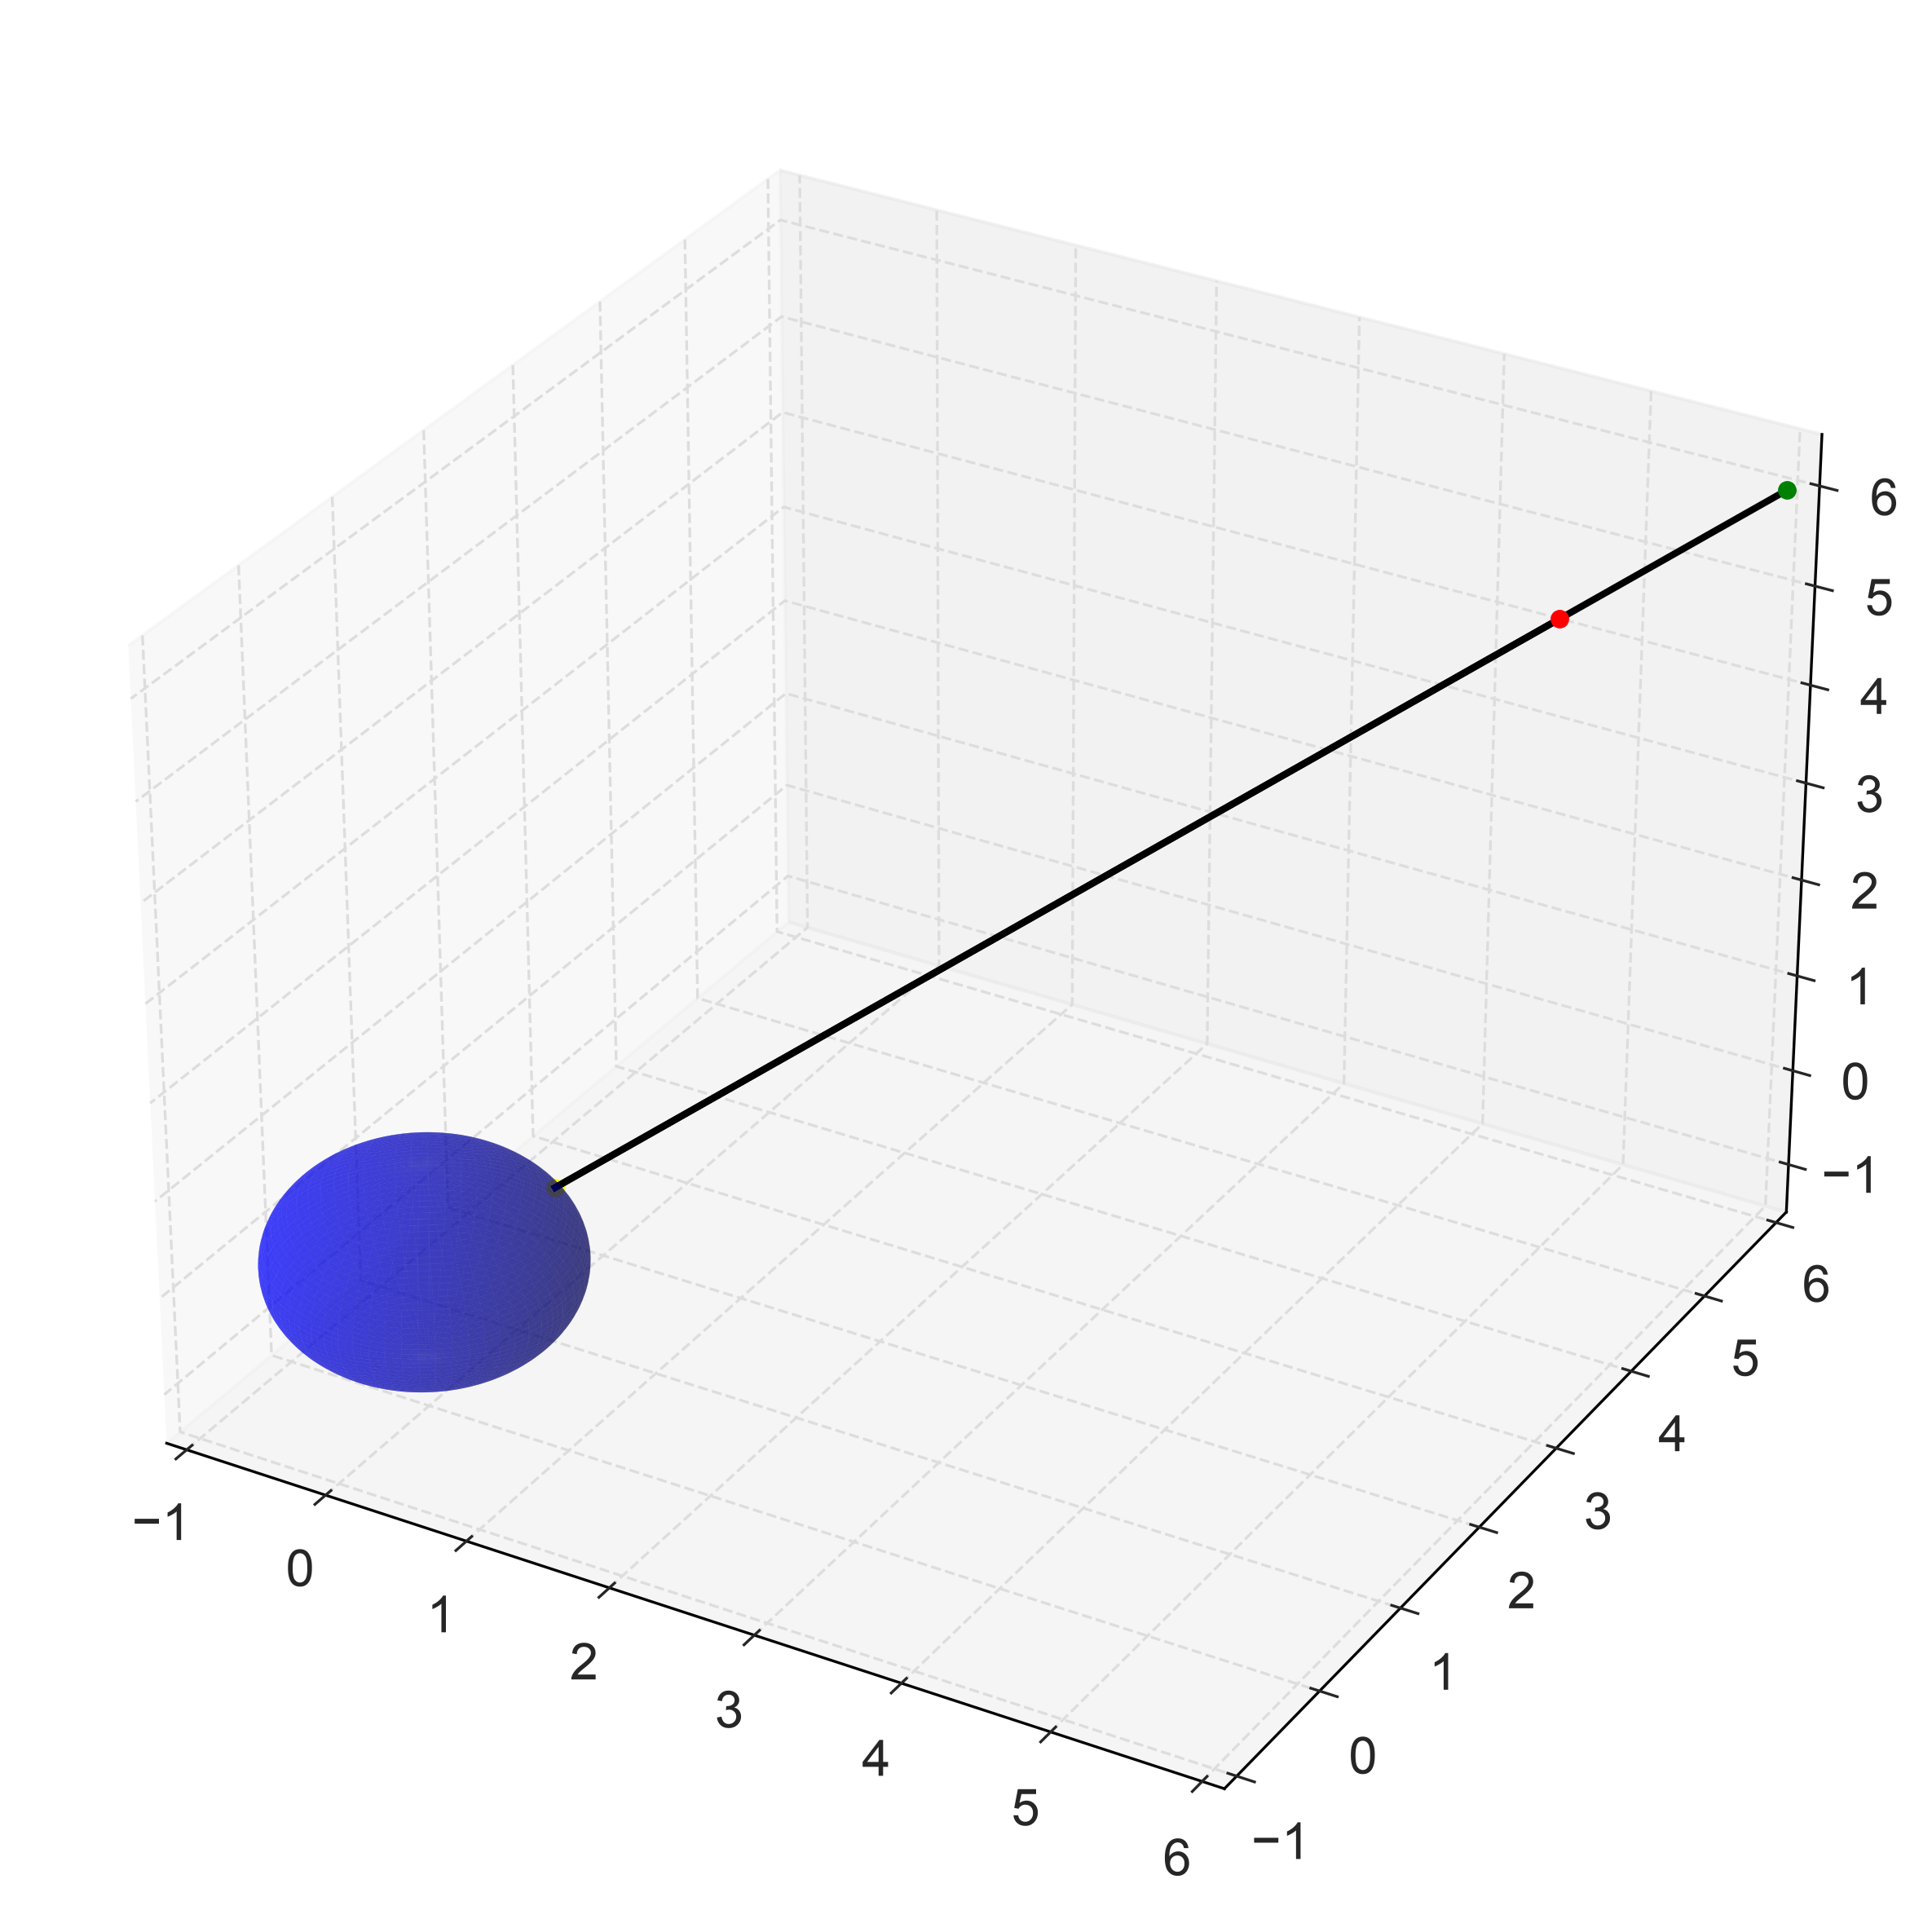

In [11]:
fig = plt.figure(figsize=(10,10), dpi=300)
ax = fig.add_subplot(111, projection='3d')

u = np.linspace(0, 2 * np.pi, 250)
v = np.linspace(0, np.pi, 250)

x = 1 * np.outer(np.cos(u), np.sin(v))
y = 1 * np.outer(np.sin(u), np.sin(v))
z = 1 * np.outer(np.ones(np.size(u)), np.cos(v))

ax.plot_surface(x, y, z,  rstride=4, cstride=4, color='b', linewidth=0, alpha=0.5)

ax.plot([5,1.0/np.sqrt(3)], [5,1.0/np.sqrt(3)], [5,1.0/np.sqrt(3)], color="black");
ax.plot([6,1.0/np.sqrt(3)], [6,1.0/np.sqrt(3)], [6,1.0/np.sqrt(3)], color="black");

ax.scatter(5,5,5, color="red");
ax.scatter(1.0/np.sqrt(3),1.0/np.sqrt(3),1.0/np.sqrt(3), color="yellow", zorder=25);
ax.scatter(6,6,6, color="green");

**Tolkning (Q1-Q2):** The total trip length is just "distance from A to the landing point C" plus "distance from C on to B". Each distance is the straight-line (Euclidean) length. For the example landing point (1,0,0) the trip is about 17.97 units long.

**Tolkning (Q3-Q4):** This is a constrained minimization: we minimize the trip length, but the landing point is only allowed to be ON the planet's surface (x²+y²+z²=1). SciPy handles this rule as an "eq" constraint, written so that it equals zero. The optimizer lands at (0.577, 0.577, 0.577), the point where the diagonal line through A and B (and the planet's center) hits the planet. It makes sense: both A and B lie on that same line, so the shortest detour is to touch down exactly where the line pierces the planet. The plot shows this as two black lines from A (red) and B (green) meeting at the yellow landing point.

### Problem 3: Portfolio optimization with constraints

One way to cast the investor's one period portfolio optimization problem (in a Markowitz framework) is to minimize the portfolio variance $\text{Var}[R_p]$

$$
\underset{\mathbf{w}}{\text{arg min}} \text{Var}[R_p] = \mathbf{w}^\top \boldsymbol{\Sigma} \mathbf{w}
$$

subject to meeting the target return $p$

$$
\mathbf{w}^\top \boldsymbol{\mu} = p
$$

We also want the portfolio weights to sum to one and not allow for short-selling

$$
\begin{align}
\mathbf{w}^\top \mathbf{1} &= 1 \\
w_i &\geq 0, \; i=1,2, ..., N
\end{align}
$$

__Question 1__

Obtain the value weighted monthly return data for the Fama-French industry portfolios ("12_Industry_Portfolios") using `pandas-datareader` since 1999-01-01. Calculate the expected monthly mean return and covariance matrix.


__Question 2__

Solve the previously defined optimization problem using the estimates from question 1. Consider different relevant target values for $p$ (expected monthly return).

__Question 3__

Plot the optimal allocation and the efficient frontier in two seperat figures.

__Question 4__

Repeat the calculations in the two previous questions when allocation to a particular index is restricted to be no more than 30%.


### Solution

__Question 1__

In [12]:
#get_available_datasets()

In [13]:
reader = FamaFrenchReader("12_Industry_Portfolios",
                          start=datetime.datetime(1999, 1, 1))
industry_port = reader.read()

# print description
industry_port['DESCR']

'12 Industry Portfolios\n----------------------\n\nThis file was created using the 202608 CRSP database. It contains value- and equal-weighted returns for 12 industry portfolios. The portfolios are constructed at the end of June. The annual returns are from January to December. Missing data are indicated by -99.99 or -999. Copyright 2026 Eugene F. Fama and Kenneth R. French\n\n  0 : Average Value Weighted Returns -- Monthly (332 rows x 12 cols)\n  1 : Average Equal Weighted Returns -- Monthly (332 rows x 12 cols)\n  2 : Average Value Weighted Returns -- Annual (27 rows x 12 cols)\n  3 : Average Equal Weighted Returns -- Annual (27 rows x 12 cols)\n  4 : Number of Firms in Portfolios (332 rows x 12 cols)\n  5 : Average Firm Size (332 rows x 12 cols)\n  6 : Sum of BE / Sum of ME (28 rows x 12 cols)\n  7 : Value-Weighted Average of BE/ME (28 rows x 12 cols)'

In [14]:
# get equally weighted
ind_eq_weighted = industry_port[1] / 100

# get market cap weighted
ind_mc_weighted = industry_port[0] / 100

# asset list
asset_list = ind_mc_weighted.columns

In [15]:
mu_est  = ind_mc_weighted.mean().values
cor_mat_est = ind_mc_weighted.corr().values
vol_est = ind_mc_weighted.std().values
cov_mat_est = np.outer(vol_est, vol_est) * cor_mat_est

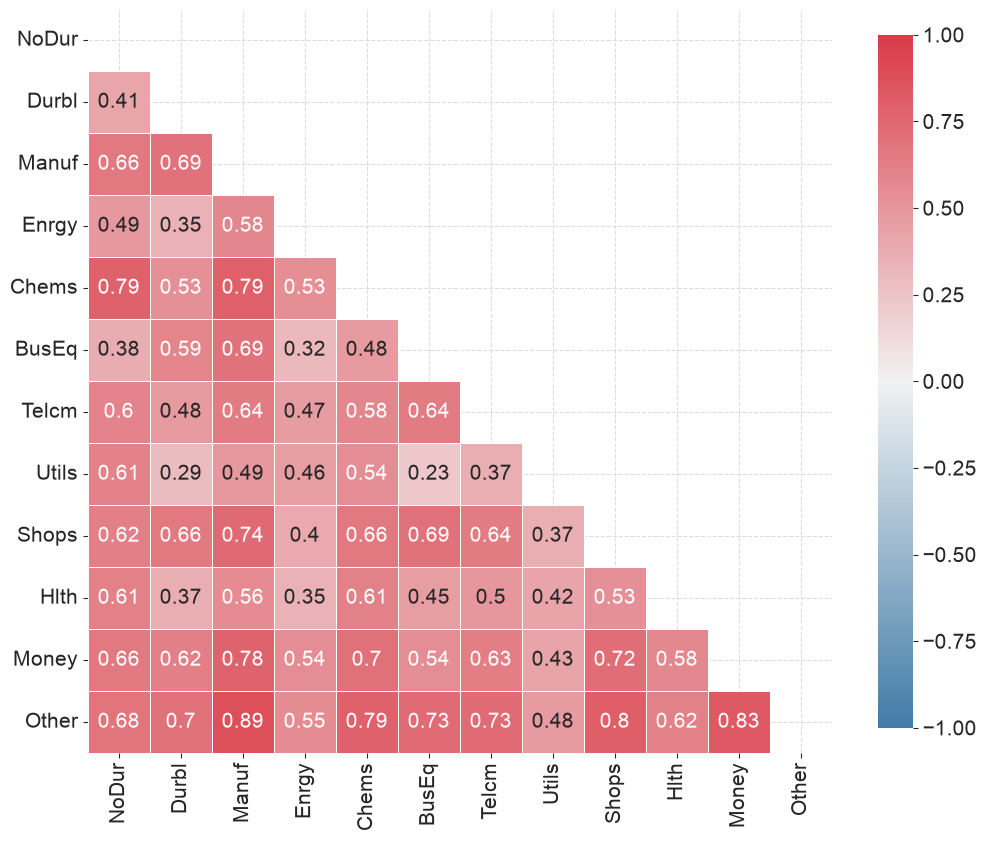

In [16]:
fig, ax = plt.subplots(figsize=(12, 12))
correlation_plot(cor_mat_est, names=asset_list, include_values=True, ax=ax)

__Question 2__

In [17]:
max_exp_ret = max(mu_est)
min_exp_ret = min(mu_est)

In [18]:
# define objective function
def portfolio_variance(w: np.ndarray, cov_mat: np.ndarray):
    return w @ cov_mat @ w

# define common constraints
sum_to_one_cons = {'type': 'eq',
                   'fun' : lambda x: np.sum(x) - 1.0,
                   'jac' : lambda x: np.ones_like(x)}

no_short_cons = {'type': 'ineq',
                 'fun' : lambda x: x,
                 'jac' : lambda x: np.eye(len(x))}

# alternatively use
bounds = [(0.0, 1.0)] * len(mu_est)

# define constraint
target_cons = {'type': 'eq',
               'fun' : lambda x: x @ mu_est - max_exp_ret,
               'jac' : lambda x: mu_est}

port_var_der = lambda w, cov_mat: 2 * w @ cov_mat


x0 = np.ones_like(mu_est) / len(mu_est)
res = optimize.minimize(portfolio_variance, x0=x0, args=(cov_mat_est,),
                        method='SLSQP',
                        jac=port_var_der,
                        constraints=[sum_to_one_cons,
                                     no_short_cons,
                                     target_cons],  # no_short_cons,
                        options={'ftol': 1e-9, 'disp': True}) #, bounds=bounds)

res

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.004743120532886877
            Iterations: 2
            Function evaluations: 2
            Gradient evaluations: 2


     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.004743120532886877
           x: [ 1.665e-16 -8.771e-15  5.551e-16 -3.456e-15  1.707e-15
                1.000e+00  2.984e-15 -2.554e-15  1.915e-15  9.159e-16
               -3.497e-15 -2.845e-15]
         nit: 2
         jac: [ 1.930e-03  7.666e-03  5.560e-03  3.125e-03  2.850e-03
                9.486e-03  4.705e-03  1.360e-03  4.417e-03  2.602e-03
                4.234e-03  5.110e-03]
        nfev: 2
        njev: 2
 multipliers: [-7.346e-02  7.478e+00 ...  1.864e-02  2.728e-02]

In [19]:
"""
Loop over different target expected return
"""

x0 = np.ones_like(mu_est) / len(mu_est)
port_weights = list()
mu_targets = np.arange(min_exp_ret, max_exp_ret, 0.0001)
for p in mu_targets:

    # define constraint
    target_cons = {'type': 'eq',
                   'fun' : lambda x: x @ mu_est - p,
                   'jac' : lambda x: mu_est}

    res = optimize.minimize(portfolio_variance, x0=x0, args=(cov_mat_est,),
                            method='SLSQP',
                            jac=port_var_der,
                            constraints=[sum_to_one_cons, target_cons],
                            options={'ftol': 1e-9, 'disp': False},bounds=bounds)

    port_weights.append(res.x)

port_weights = np.array(port_weights) * 100

In [20]:
#port_weights
#mu_targets

__Question 3__

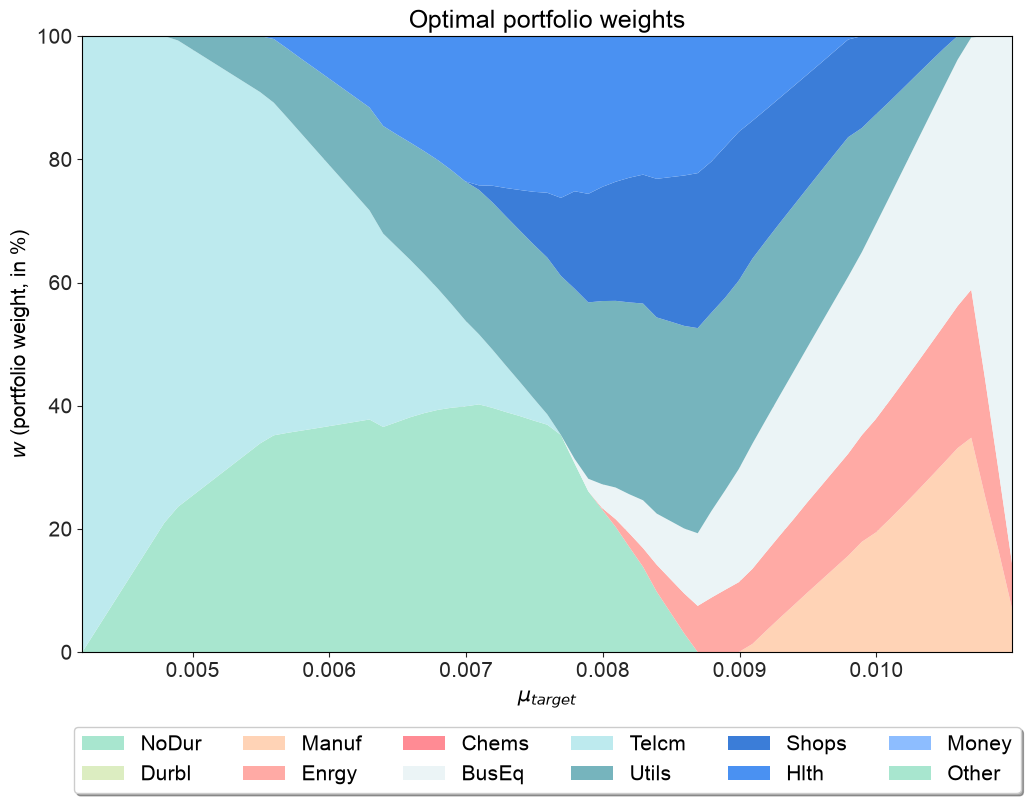

In [21]:
fig, ax = plt.subplots(figsize=(12, 8))

ax.stackplot(mu_targets, port_weights.T, labels=asset_list);
ax.set_xlabel('$\\mu_{target}$')
ax.set_ylabel('$w$ (portfolio weight, in %)');
ax.set_title('Optimal portfolio weights');
ax.legend(loc='center', bbox_to_anchor=(0.5, -0.175),
          fancybox=True, shadow=True, ncol=6);

In [22]:
port_weights.shape

(69, 12)

(0.0031930722891566265, 0.012091566265060243)

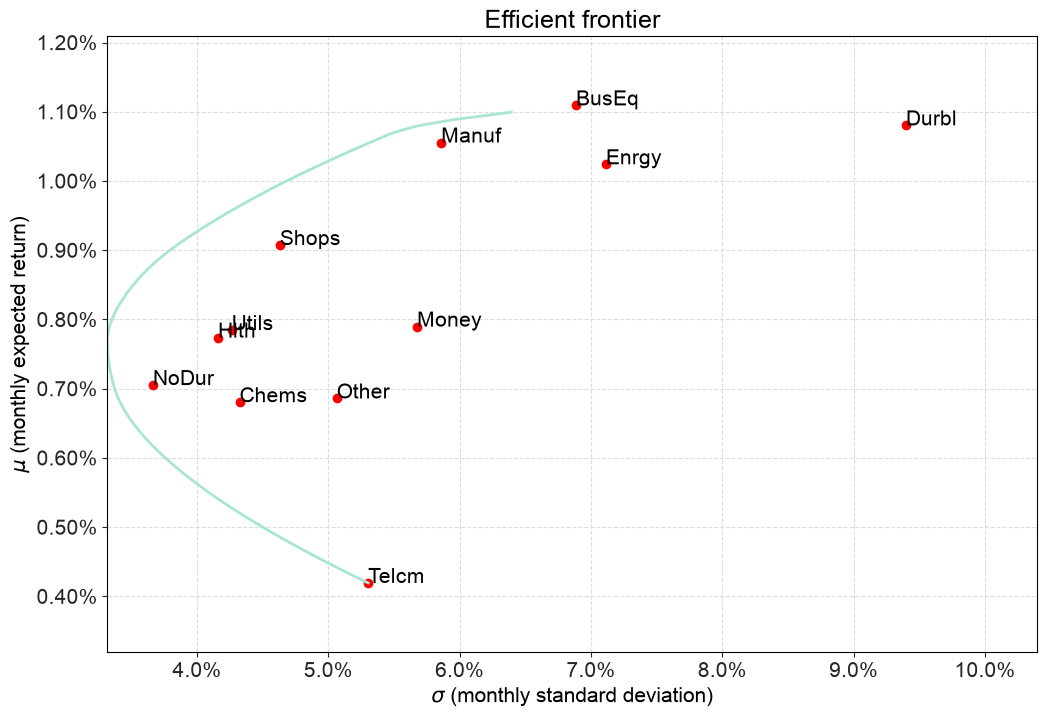

In [23]:
all_port_std = np.sqrt(np.apply_along_axis(portfolio_variance, 1,
                                           port_weights / 100, cov_mat_est))
all_mu = port_weights @ mu_est / 100.0


fig, ax = plt.subplots(figsize=(12,8))

ax.plot(all_port_std, all_mu, label='Efficient frontier')
ax.scatter(vol_est, mu_est, color="red", label="Individual assets");
ax.set_title('Efficient frontier');

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))

ax.set_xlabel('$\\sigma$ (monthly standard deviation)')
ax.set_ylabel('$\\mu$ (monthly expected return)');

# add asset names
for i, xy in enumerate(zip(vol_est, mu_est)):
    ax.annotate(asset_list[i], xy)

# fix axes
ax.set_xlim([ax.get_xlim()[0], ax.get_xlim()[1] + 0.01])
ax.set_ylim([ax.get_ylim()[0] - 0.001, ax.get_ylim()[1] + 0.001])

__Question  4__

In [24]:
bounds = [(0.0, 0.3)] * len(mu_est) # implement constraint
x0 = np.ones_like(mu_est) / len(mu_est)
port_weights = list()
mu_targets = np.arange(min_exp_ret + 0.003, max_exp_ret - 0.0005, 0.0001)
for p in mu_targets:

    # define constraint
    target_cons = {'type': 'eq',
               'fun' : lambda x: x @ mu_est - p,
               'jac' : lambda x: mu_est}

    res = optimize.minimize(portfolio_variance, x0=x0, args=(cov_mat_est,),
                            method='SLSQP',
                            jac=port_var_der,
                            constraints=[sum_to_one_cons, target_cons],
                            options={'ftol': 1e-9, 'disp': False}, bounds=bounds)

    port_weights.append(res.x)

port_weights = np.array(port_weights) * 100

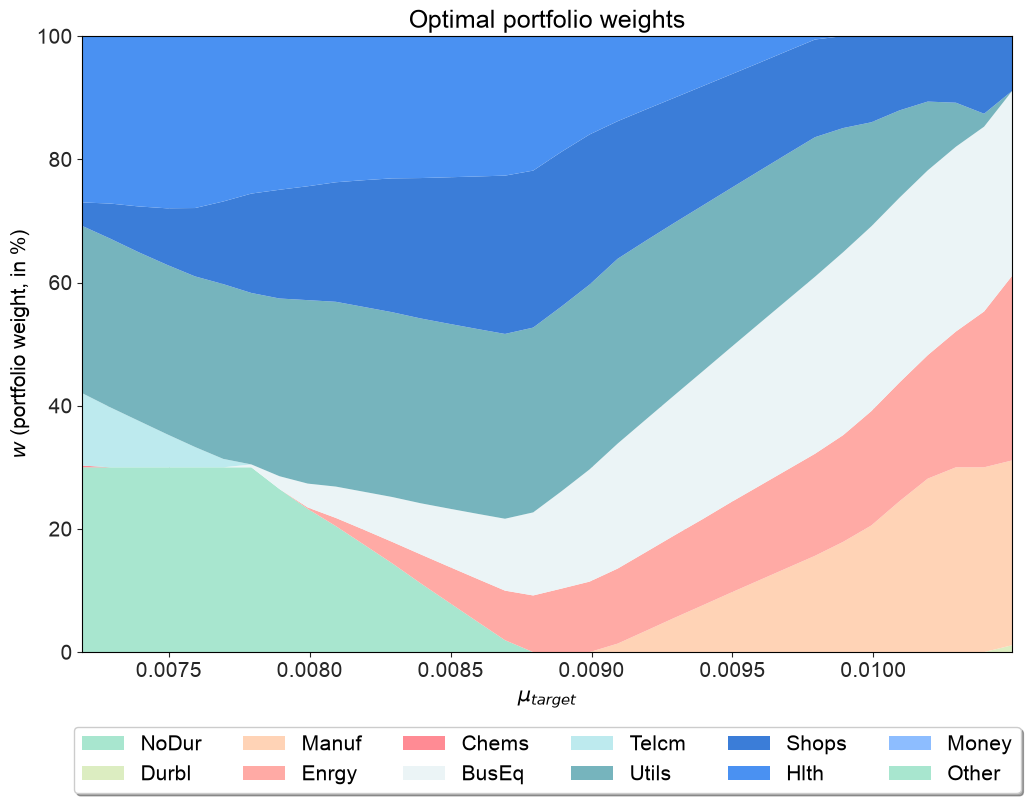

In [25]:
fig, ax = plt.subplots(figsize=(12, 8))

ax.stackplot(mu_targets, port_weights.T, labels=asset_list);
ax.set_xlabel('$\\mu_{target}$')
ax.set_ylabel('$w$ (portfolio weight, in %)');
ax.set_title('Optimal portfolio weights');
ax.legend(loc='center', bbox_to_anchor=(0.5, -0.175),
          fancybox=True, shadow=True, ncol=6);

(0.0031930722891566265, 0.012091566265060243)

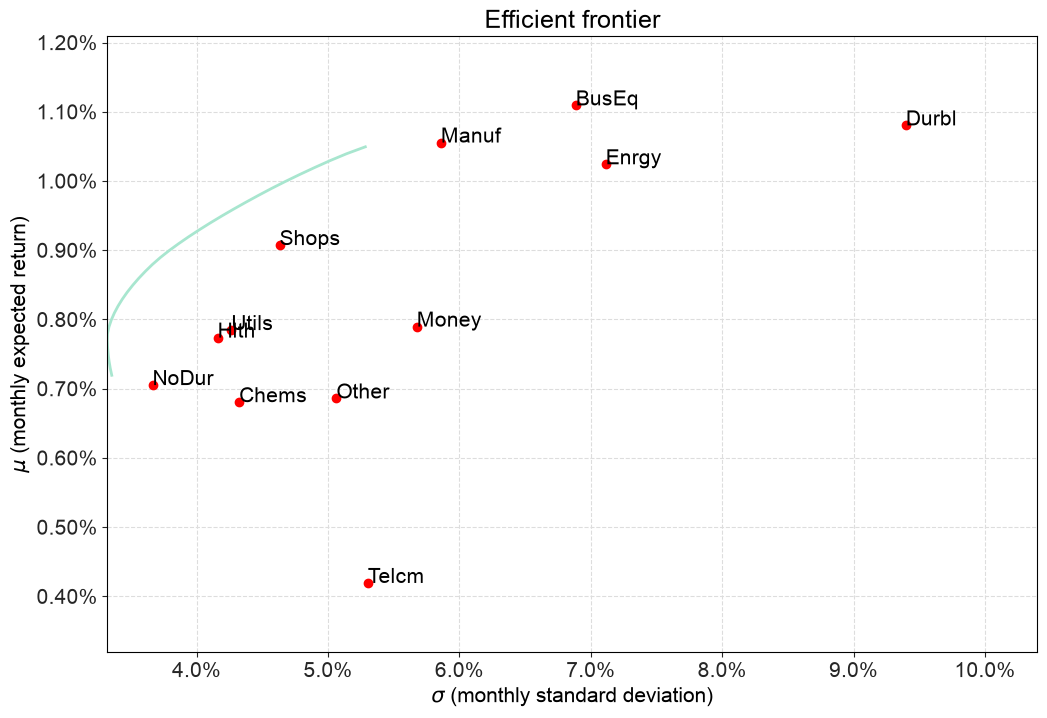

In [26]:
all_port_std = np.sqrt(np.apply_along_axis(portfolio_variance, 1, port_weights / 100, cov_mat_est))
all_mu = port_weights @ mu_est / 100.0


fig, ax = plt.subplots(figsize=(12,8))

ax.plot(all_port_std, all_mu, label='Efficient frontier')
ax.scatter(vol_est, mu_est, color="red", label="Individual assets");
ax.set_title('Efficient frontier');

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))

ax.set_xlabel('$\\sigma$ (monthly standard deviation)')
ax.set_ylabel('$\\mu$ (monthly expected return)');


# add asset names
for i, xy in enumerate(zip(vol_est, mu_est)):
    ax.annotate(asset_list[i], xy)

# fix axes
ax.set_xlim([ax.get_xlim()[0], ax.get_xlim()[1] + 0.01])
ax.set_ylim([ax.get_ylim()[0] - 0.001, ax.get_ylim()[1] + 0.001])

**Tolkning (Q1):** We download monthly returns for 12 US industries since 1999 and estimate the two inputs every portfolio optimization needs: the average return of each industry (mu) and how they move together (the covariance matrix, built from volatilities and correlations). The correlation plot shows which industries tend to move together and which are more independent.

**Tolkning (Q2):** For each return target p, the optimizer finds the least risky portfolio that earns exactly p, subject to "weights sum to 1" and "no shorting". Looping over many targets from the lowest to the highest asset return gives a whole family of optimal portfolios. At the very highest target, the only way to earn that return without shorting is to put everything in the single best-performing industry.

**Tolkning (Q3):** The weights plot shows how the best portfolio changes as we ask for more return: at low targets it is spread across several industries, and as the target rises it shifts toward the industries with the highest average returns until it ends in a single one. The frontier plot shows the price of return in terms of risk. The red dots (single industries) lie to the right of or below the frontier, which shows the benefit of diversification: a mix of industries gives less risk for the same return than holding one industry alone. (Note: if the lowest target is below the return of the minimum-variance portfolio, the bottom part of the curve is the inefficient half. The truly efficient frontier is the part above the minimum-variance point.)

**Tolkning (Q4):** Capping every industry at 30% forces the portfolio to be more diversified, so the weights plot no longer ends with 100% in one industry. The price is that an extra rule can never improve the result: for the same return, the constrained portfolio has equal or higher risk, so the new frontier lies to the right of (or on) the unconstrained one. The range of possible return targets also shrinks, because with a 30% cap the very highest returns can no longer be reached.

## Problem 4:  Minimizing CVaR (and VaR)

We now assume that an investor's one period portfolio optimization problem is to minimize the portfolio $\text{CVaR}_\beta[R_p]$

$$
\underset{\mathbf{w}}{\text{arg min }}  \text{CVaR}_\beta[R_p]
$$

subject to meeting the target return $p$

$$
\mathbf{w}^\top \boldsymbol{\mu} = p
$$

We also want the portfolio weights to sum to one and not allow for short-selling

$$
\begin{align}
\mathbf{w}^\top \mathbf{1} &= 1 \\
w_i &\geq 0, \; i=1,2, ..., N
\end{align}
$$


__Question 1__

Implement the Mean-CVaR optimization problem using the same data set as in the previous problem for some target return. Let $\beta = 0.95$ (95% CVaR).


__Question 2__

Consider different relevant target values for $p$ (expected monthly return).

Plot the optimal allocations and the efficient frontier.

### Solution

__Question 1__

In [27]:
reader = FamaFrenchReader("12_Industry_Portfolios", start=datetime.datetime(1999, 1, 1))
industry_port = reader.read()

# print description
industry_port['DESCR']

# get equally weighted
ind_eq_weighted = industry_port[1] / 100

# get market cap weighted
ind_mc_weighted = industry_port[0] / 100

# asset list
asset_list = ind_mc_weighted.columns

In [28]:
mu_est  = ind_mc_weighted.mean().values
cor_mat_est = ind_mc_weighted.corr().values
vol_est = ind_mc_weighted.std().values
cov_mat_est = np.outer(vol_est, vol_est)*cor_mat_est

In [29]:
def calculate_cvar(w: np.ndarray, returns: np.ndarray, beta: float = 0.95):

    # portfolio returns
    port_returns = returns @ w

    # percentile
    perc = np.percentile(port_returns, (1 - beta)*100)

    # average in tail
    avg_tail = np.mean(port_returns[port_returns <= perc])

    return -avg_tail

In [30]:
# define common constraints
sum_to_one_cons = {'type': 'eq',
                   'fun' : lambda x: np.sum(x) - 1.0}

no_short_cons = {'type': 'ineq',
                 'fun' : lambda x: x}

# alternatively use
bounds = [(0.0, 1.0)] * len(mu_est)

# define constraint
target_cons = {'type': 'eq',
               'fun' : lambda x: x @ mu_est - 0.009}


x0 = np.ones_like(mu_est) / len(mu_est)
res1 = optimize.minimize(calculate_cvar, x0=x0, args=(ind_mc_weighted.values, 0.95),
                        method='SLSQP',
                        constraints=[sum_to_one_cons,  target_cons],
                        options={'ftol': 1e-9, 'disp': True}, bounds=bounds)

res1

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.08071392155338761
            Iterations: 45
            Function evaluations: 690
            Gradient evaluations: 45


     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.08071392155338761
           x: [ 1.863e-16  9.745e-18  9.812e-17  8.592e-02  4.588e-19
                1.080e-01  1.569e-17  1.452e-18  5.126e-01  2.934e-01
                3.263e-19  1.713e-17]
         nit: 45
         jac: [ 5.875e-02  1.252e-01  1.165e-01  9.512e-02  7.136e-02
                1.095e-01  8.372e-02  7.514e-02  8.169e-02  6.419e-02
                9.707e-02  1.043e-01]
        nfev: 690
        njev: 45
 multipliers: [-4.029e-02  1.343e+01]

__Question 2__

In [31]:
max_exp_ret = max(mu_est)
min_exp_ret = min(mu_est)
x0 = np.r_[np.ones_like(mu_est) / len(mu_est)]
port_weights = list()
mu_targets = np.arange(min_exp_ret + 0.003, max_exp_ret - 0.0005, 0.0001)
for p in mu_targets:

    # define constraint
    target_cons = {'type': 'eq',
                   'fun' : lambda x: x @ mu_est - p}

    res = optimize.minimize(calculate_cvar, x0=x0, args=(ind_mc_weighted.values, 0.95),
                        method='SLSQP',
                        constraints=[sum_to_one_cons,  target_cons],
                        options={'ftol': 1e-12, 'disp': True, 'maxiter': 1000, 'eps': 1e-12}, bounds=bounds)

    port_weights.append(res.x)

port_weights = np.array(port_weights)

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.0717459607035466
            Iterations: 81
            Function evaluations: 1186
            Gradient evaluations: 81
Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.0713858364919063
            Iterations: 61
            Function evaluations: 875
            Gradient evaluations: 61
Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.07107615271117078
            Iterations: 66
            Function evaluations: 967
            Gradient evaluations: 66
Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.07077241608841578
            Iterations: 51
            Function evaluations: 757
            Gradient evaluations: 51
Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.07046799384756086
            Iterations: 66
            Func

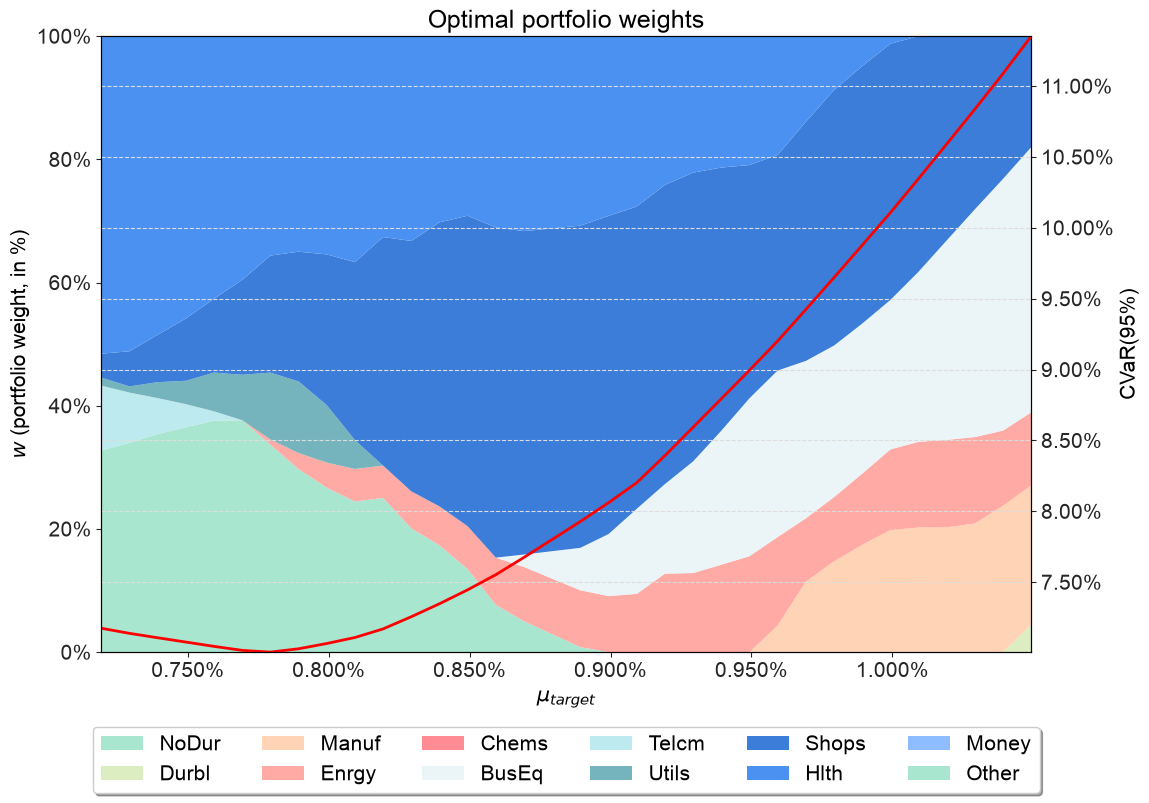

In [32]:
"""
Plotting
"""

fig, ax = plt.subplots(figsize=(12, 8))

ax.stackplot(mu_targets, port_weights.T, labels=asset_list);
ax.set_xlabel('$\\mu_{target}$')
ax.set_ylabel('$w$ (portfolio weight, in %)');
ax.set_title('Optimal portfolio weights');
ax.legend(loc='center', bbox_to_anchor=(0.5, -0.175),
          fancybox=True, shadow=True, ncol=6);
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))


all_port_cvar = np.apply_along_axis(calculate_cvar, 1, port_weights , ind_mc_weighted.values, 0.95)
all_mu = port_weights @ mu_est

ax_new = ax.twinx()
ax_new.plot(all_mu, all_port_cvar,  color="red")

ax_new.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax_new.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax_new.set_ylabel('CVaR(95%)');

**Tolkning (Q1):** Instead of minimizing the variance, we now minimize the average loss in the worst 5% of months (CVaR 95%), calculated directly from the historical returns without assuming any distribution. The constraints are the same as before: weights sum to 1, no shorting, and the portfolio must earn the target return (0.9% per month). So this finds the portfolio with the smallest "bad-tail" loss for that return.

**Tolkning (Q2):** We repeat the optimization for many return targets and plot two things together: how the optimal weights change (colored areas) and how the smallest achievable CVaR grows with the target return (red line, right axis). The red line slopes upward because demanding more return forces the portfolio into riskier positions, so the average loss in bad months rises. The optimizer settings are very tight because CVaR from historical data is not a smooth function, which makes it harder for the solver than the variance in Problem 3.

## Problem 5: Classical Mean-Variance optimization with constraints

An investor can invest in 10 different assets: Government bonds, Investment-grade bonds, High-yield bonds, Emerging markets gov. bonds, Equities (developed markets), Equities (Emerging markets), Private equity, Infrastructure, Real Estate, and Hedgefunds.  The continuously compounded / log-returns are assumed to be i.i.d. multivariate normally distributed

\begin{equation*}
	\mathbf{r}_{t + 1, 1} \sim MVN(\boldsymbol{\mu},\boldsymbol{\Sigma})
\end{equation*}

with correlation matrix

\begin{equation*}
	\mathbf{C} =   \begin{bmatrix}
		1.0 &  0.6 &  0.1 &  0.3 & -0.1 & -0.1 & -0.2 & -0.1 & -0.1 & -0.1 \\
		0.6 &  1.0 &  0.6 &  0.6 &  0.2 &  0.2 &  0.2 &  0.1 &  0.1 &  0.3 \\
		0.1 &  0.6 &  1.0 &  0.7 &  0.7 &  0.6 &  0.6 &  0.4 &  0.3 &  0.7 \\
		0.3 &  0.6 &  0.7 &  1.0 &  0.5 &  0.6 &  0.4 &  0.2 &  0.2 &  0.5 \\
		-0.1 &  0.2 &  0.7 &  0.5 &  1.0 &  0.7 &  0.8 &  0.4 &  0.4 &  0.8 \\
		-0.1 &  0.2 &  0.6 &  0.6 &  0.7 &  1.0 &  0.7 &  0.4 &  0.4 &  0.7 \\
		-0.2 &  0.2 &  0.6 &  0.4 &  0.8 &  0.7 &  1.0 &  0.4 &  0.4 &  0.7 \\
		-0.1 &  0.1 &  0.4 &  0.2 &  0.4 &  0.4 &  0.4 &  1.0 &  0.3 &  0.4 \\
		-0.1 &  0.1 &  0.3 &  0.2 &  0.4 &  0.4 &  0.4 &  0.3 &  1.0 &  0.4 \\
		-0.1 &  0.3 &  0.7 &  0.5 &  0.8 &  0.7 &  0.7 &  0.4 &  0.4 &  1.0
	\end{bmatrix},
\end{equation*}

vector of volatilities

\begin{equation*}
	\mathbf{v} =   \begin{bmatrix}
		0.037, 0.055, 0.119, 0.107, 0.153, 0.217, 0.204, 0.14, 0.108, 0.094
	\end{bmatrix}^\top,
\end{equation*}

and expected log return


\begin{equation*}
	\boldsymbol{\mu} =   \begin{bmatrix}
		0.019, 0.022, 0.049, 0.043, 0.061, 0.083, 0.102, 0.056, 0.041, 0.038
	\end{bmatrix}^\top - \frac{1}{2} \text{Diag}(\boldsymbol{\Sigma}),
\end{equation*}

__Question 1__


Assume that $\mathbf{P}_0 = 1$. What is the distribution of the net portfolio return $\mathbf{w}^\top \mathbf{R}_1 = \mathbf{w}^\top \frac{\mathbf{P}_1}{\mathbf{P}_0} - 1$?  What is the expected portfolio return and standard deviation?


__Question 2__

Calculate the expected value and standard devation of an equally weighted portfolio. Calculate and visualize the risk contribution based on standard deviation as risk measure.

__Question 3__

Define and solve the minimization problem using `cvxopt` or `cvxpy`

$$
\begin{align*}
	\min_{\mathbf{x}}  \quad & \mathbf{w}^\top  \text{Cov}[\mathbf{R}_1]  \mathbf{w} \\
	\textrm{s.t.} \quad
     & \mathbf{1}^\top \mathbf{w} = 1\\
     & \text{E}[\mathbf{R}_1]^\top \mathbf{w} = \bar{\mu}\\
	 & \mathbf{w} \geq \mathbf{0}
\end{align*}
$$

Thus, minimize the portfolio variance subject to a given target return $\bar{\mu}$. Consider 50 different return targets from the lowest to the highest possible.

Plot the optimal portfolio weights using a `matplotlib.pyplot.stackplot` for the return targets.

__Question 4__

Using the optimal portfolios from above, plot the efficient frontier (plot the standard deviations against the expected return). Add the assets to the plot.

__Question 5__

The optimal portfolios are dominated by a few assets. We want to impose a maximum allocation of $0.25$. Furthermore, we want to impose a maximum allocation of $0.4$ to alternatives: Private equity, Infrastructure, Real Estate, Hedgefunds.

Repeat the last two questions, when imposing these constraints.


### Solution

__Question 1__

We have assumed that the log-returns follow a multivariate normal distribution

$$
\mathbf{r}_{t+ 1, 1} = \log \frac{\mathbf{P}_{t+1}}{\mathbf{P}_t} \sim MVN(\boldsymbol{\mu}, \boldsymbol{\Sigma})
$$

Thus, the vector of asset prices at year one follows a multivariate log-normal distribution

$$
\log \mathbf{P}_1 \sim MVN(\boldsymbol{\mu}, \boldsymbol{\Sigma}) \Leftrightarrow \mathbf{P}_1 \sim \log MVN(\boldsymbol{\mu}, \boldsymbol{\Sigma})
$$

The value of the portfolio in one year $\mathbf{w}^\top \mathbf{P}_1$ does not follow a log-normal since the weighted sum of log-normals does not follow a log-normal distribution! However, it is possible to derive the expected value and the variance


We need to find the expected value and covariance of the linear returns. We have

$$
\text{E}[e^{\mathbf{r}_{1, 1}}] = \text{E}[\mathbf{P}_{1}] = e^{\boldsymbol{\mu}   + \frac{1}{2}\text{diag}(\boldsymbol{\Sigma})}
$$

and

$$
\text{Cov}[e^{\mathbf{r}_{1, 1}}] =  \text{Cov}[\mathbf{P}_{1}] =  \text{E}[e^{\mathbf{r}_{1, 1}}] \text{E}[e^{\mathbf{r}_{1,1}}]^\top \odot \left(e^{\boldsymbol{\Sigma}} - \mathbf{1} \right)
$$

The expected value and covariance of the linear returns are therefore

$$
\text{E}[\mathbf{R}_{1}] = \text{E}[\mathbf{P}_{1} - 1 ] = e^{\boldsymbol{\mu}  + \frac{1}{2}\text{diag}(\boldsymbol{\Sigma})} - 1
$$

and

$$
\text{Cov}[\mathbf{R}_{1}] =  \text{Cov}[\mathbf{P}_{1}] =  \text{E}[e^{\mathbf{r}_{1, 1}}] \text{E}[e^{\mathbf{r}_{1,1}}]^\top \odot \left(e^{\boldsymbol{\Sigma}} - \mathbf{1} \right)
$$


The portfolio return

$$
R_w = \mathbf{w}^\top \mathbf{R}_1
$$

has the expected value

$$
\text{E}[R_w] =  \mathbf{w}^\top \text{E}[\mathbf{R}_{1}]
$$

and variance

$$
\text{Var}[R_w] = \mathbf{w}^\top \text{Cov}[\mathbf{R}_{1}] \mathbf{w}
$$

__Question 2__

In [33]:
"""
Define inputs
"""

asset_names = ["Government bonds", "Investment-grade bonds", "High-yield bonds",
               "Emerging markets gov. bonds", "Equities (developed markets)",
               "Equities (Emerging markets)", "Private equity", "Infrastructure",
               "Real Estate", "Hedgefunds"]

corr_mat = np.array([[1.00, 0.60, 0.10, 0.30, -0.10, -0.10, -0.20, -0.10, -0.10, -0.10],
                     [0.60, 1.00, 0.60, 0.60, 0.20, 0.20, 0.20, 0.10, 0.10, 0.30],
                     [0.10, 0.60, 1.00, 0.70, 0.70, 0.60, 0.60, 0.40, 0.30, 0.70],
                     [0.30, 0.60, 0.70, 1.00, 0.50, 0.60, 0.40, 0.20, 0.20, 0.50],
                     [-0.10, 0.20, 0.70, 0.50, 1.00, 0.70, 0.80, 0.40, 0.40, 0.80],
                     [-0.10, 0.20, 0.60, 0.60, 0.70, 1.00, 0.70, 0.40, 0.40, 0.70],
                     [-0.20, 0.20, 0.60, 0.40, 0.80, 0.70, 1.00, 0.40, 0.40, 0.70],
                     [-0.10, 0.10, 0.40, 0.20, 0.40, 0.40, 0.40, 1.00, 0.30, 0.40],
                     [-0.10, 0.10, 0.30, 0.20, 0.40, 0.40, 0.40, 0.30, 1.00, 0.40],
                     [-0.10, 0.30, 0.70, 0.50, 0.80, 0.70, 0.70, 0.40, 0.40, 1.00]])

vols = np.array([3.7, 5.5, 11.9, 10.7, 15.3, 21.7, 20.4, 14.0, 10.8, 9.4]) / 100.0

cov_mat = mom.corr_to_cov_matrix(corr_mat=corr_mat, vols=vols)

mu = np.array([1.9, 2.2, 4.9, 4.3, 6.1, 8.3, 10.2, 5.6, 4.1, 3.8]) / 100 - 0.5 * vols**2

# number of assets
num_assets = len(mu)

# equal portfolio weights
eq_w = np.repeat(1.0 / num_assets, num_assets)

In [34]:
"""
Convert to mean and variance for linear returns
"""

mu_l = mom.calculate_log_norm_mean(mu, cov_mat) - 1.0
sigma_l = mom.calculate_log_norm_cov_mat(mu, cov_mat)

In [35]:
df_res = pd.DataFrame(columns=["Eq. weighted"], dtype=np.float64)
df_res.loc['$\\mu_p$', :] = rm.calculate_portfolio_mean(weights=eq_w, mu=mu_l) * 100.0
df_res.loc['$\\sigma_p$', :] = rm.calculate_portfolio_std(weights=eq_w, cov_mat=sigma_l) * 100.0

df_res.round(2)

,Eq. weighted
$\mu_p$,5.31
$\sigma_p$,9.68


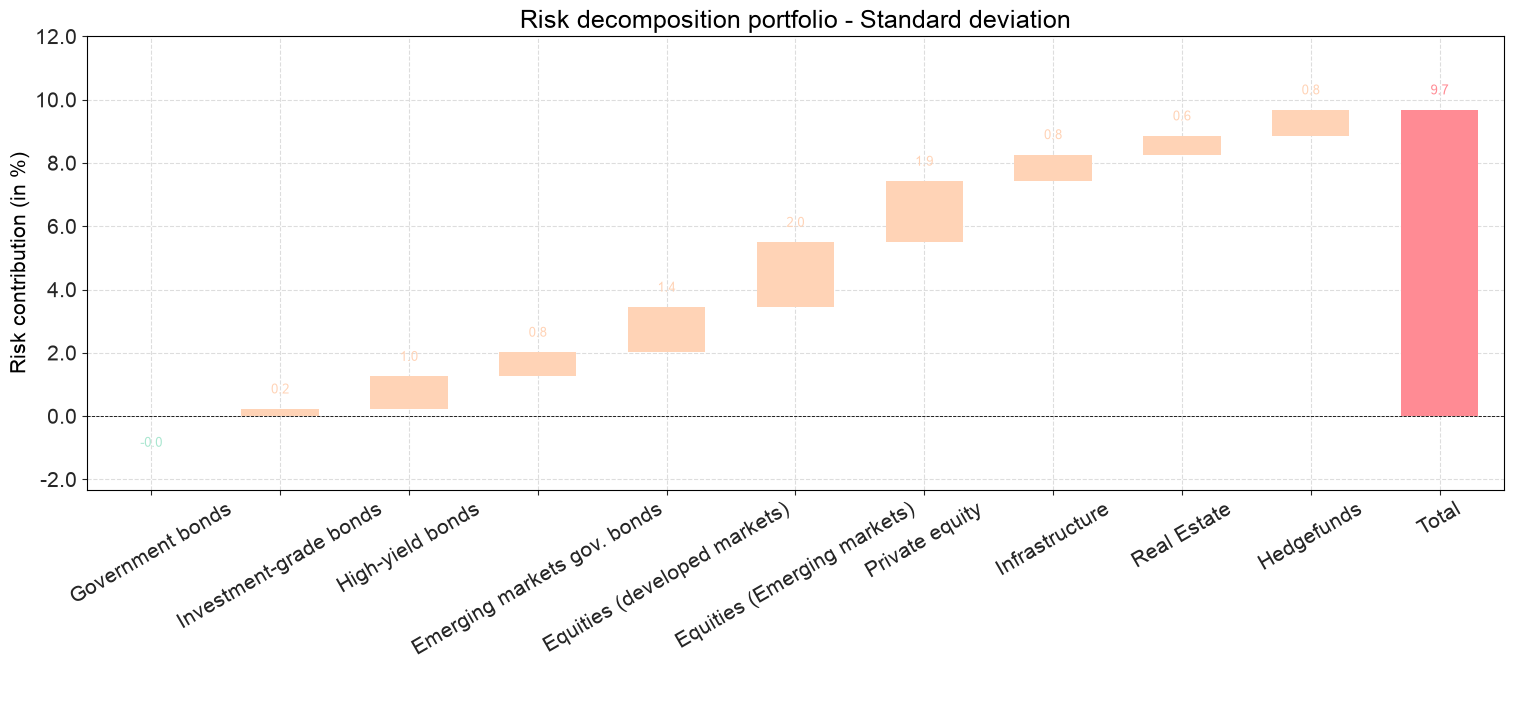

In [36]:
"""
Calculate risk contributions
"""

std_contrib = rb.calculate_risk_contributions_std(weights=eq_w, cov_mat=sigma_l)

"""
Plot waterfall chart
"""

waterfall_chart(labels=asset_names, values=std_contrib*100)

fig = plt.gcf()
ax = plt.gca()
fig.set_size_inches(18.5, 10.5)
ax.set_title('Risk decomposition portfolio - Standard deviation')
ax.set_ylabel('Risk contribution (in %)');

__Question 3__

In [37]:
"""
Define problem
"""

# return targets to consider
return_targets = np.linspace(np.min(mu_l), np.max(mu_l), 100)

# define cvxpy parameter
mu_target = cp.Parameter()

# optimization variable
w = cp.Variable(num_assets)

# define constraints
constraints = [w >= 0]
constraints.append(cp.sum(w) == 1)
constraints.append(w @ mu_l == mu_target)

# define problem
variance = cp.quad_form(w, sigma_l, assume_PSD=True)
prob =  cp.Problem(cp.Minimize(variance), constraints)

In [38]:
"""
Iterate over all possible return targets
"""

# define list for storing optimal portfolios
optimal_portfolios = []

for mu in return_targets:

    # set expected return target
    mu_target.value = mu

    # solve problem
    prob.solve(verbose=False)

    # store optimal weights
    optimal_portfolios.append(w.value)

# transform to numpy array
optimal_portfolios = np.array(optimal_portfolios)

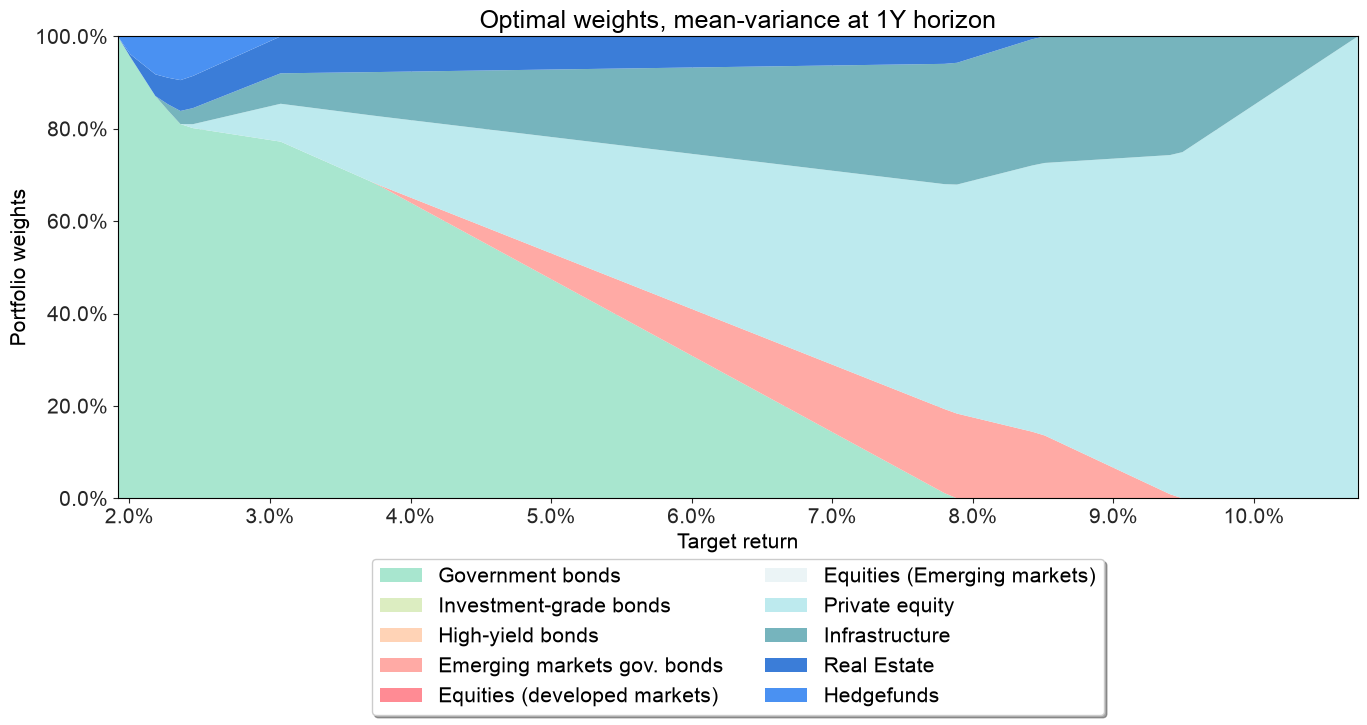

In [39]:
"""
Plot portfolio along the efficient frontier
"""

fig, ax = plt.subplots(figsize=(16, 6))

ax.stackplot(return_targets, optimal_portfolios.T, labels=asset_names);
ax.set_xlabel("Target return")
ax.set_ylabel("Portfolio weights")
ax.set_title("Optimal weights, mean-variance at 1Y horizon")
ticks = mtick.PercentFormatter(1)
ax.yaxis.set_major_formatter(ticks)
ax.xaxis.set_major_formatter(ticks)
ax.legend(loc='center', bbox_to_anchor=(0.5, -0.3),
          fancybox=True, shadow=True, ncol=2);

__Question 4__

In [40]:
"""
Calculate port. expected return along efficient frontier
"""

eff_port_exp_return = np.apply_along_axis(rm.calculate_portfolio_mean,
                                          1, optimal_portfolios, mu_l)

"""
Calculate port. std
"""

eff_port_std = np.apply_along_axis(rm.calculate_portfolio_std,
                                   1, optimal_portfolios, sigma_l)

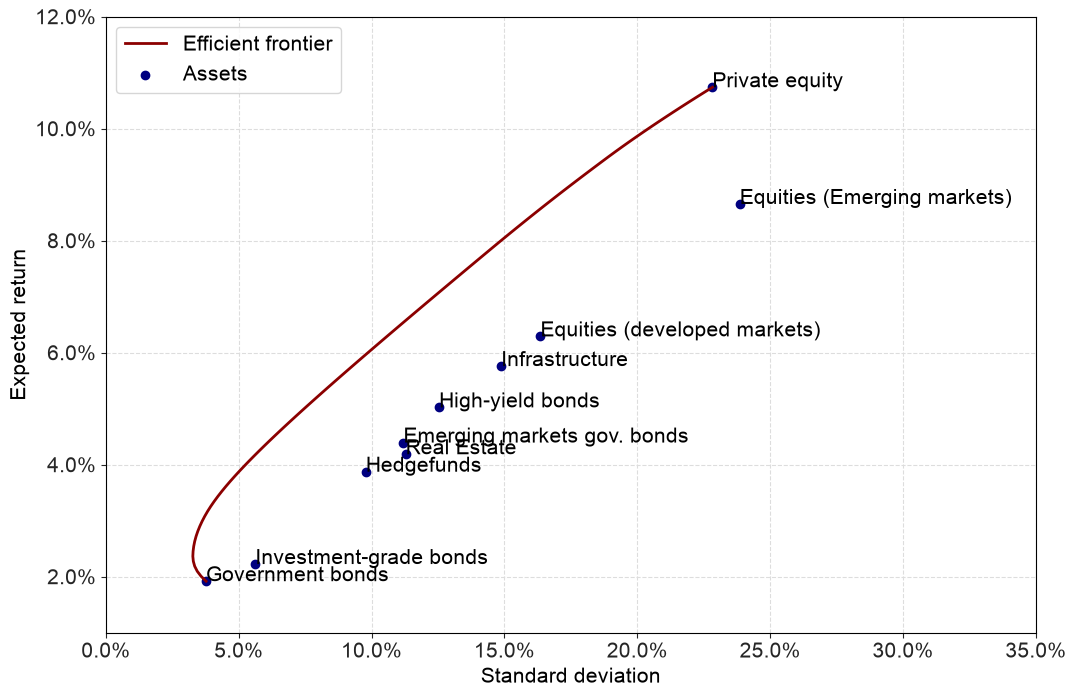

In [41]:
fig, ax = plt.subplots(figsize=(12, 8))

# plot efficient frontier
ax.plot(eff_port_std, eff_port_exp_return, label="Efficient frontier",
        color="darkred")

# add the different assets
assets_std = np.sqrt(np.diag(sigma_l))
ax.scatter(assets_std, mu_l, color="navy", label="Assets")
for i in range(num_assets):
    ax.annotate(asset_names[i], (assets_std[i], mu_l[i]))

# set correct tick labels, etc.
ticks = mtick.PercentFormatter(1)
ax.yaxis.set_major_formatter(ticks)
ax.xaxis.set_major_formatter(ticks)

ax.set(xlabel="Standard deviation", ylabel="Expected return")

ax.set_xlim([0.0, 0.35])
ax.set_ylim([0.01, 0.12])
ax.legend(loc="upper left");

__Question 5__

In [42]:
"""
Define problem
"""

# return targets to consider
return_targets = np.linspace(np.min(mu_l) + 0.015, np.max(mu_l) - 0.03, 100)

# define cvxpy parameter
mu_target = cp.Parameter()

# optimization variable
w = cp.Variable(num_assets)

# define constraints
constraints = [w >= 0]
constraints.append(cp.sum(w) == 1)
constraints.append(w @ mu_l == mu_target)
constraints.append(w<=0.25)
constraints.append(np.array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1]) @ w <= 0.4)

# define problem
variance = cp.quad_form(w, sigma_l, assume_PSD=True)
prob =  cp.Problem(cp.Minimize(variance), constraints)

In [43]:
"""
Iterate over all possible return targets
"""

# define list for storing optimal portfolios
optimal_portfolios_w_max_alloc = []

for mu in return_targets:

    # set expected return target
    mu_target.value = mu

    # solve problem
    prob.solve(verbose=False, solver='OSQP')

    # store optimal weights
    optimal_portfolios_w_max_alloc.append(w.value)

# transform to numpy array
optimal_portfolios_w_max_alloc = np.array(optimal_portfolios_w_max_alloc)

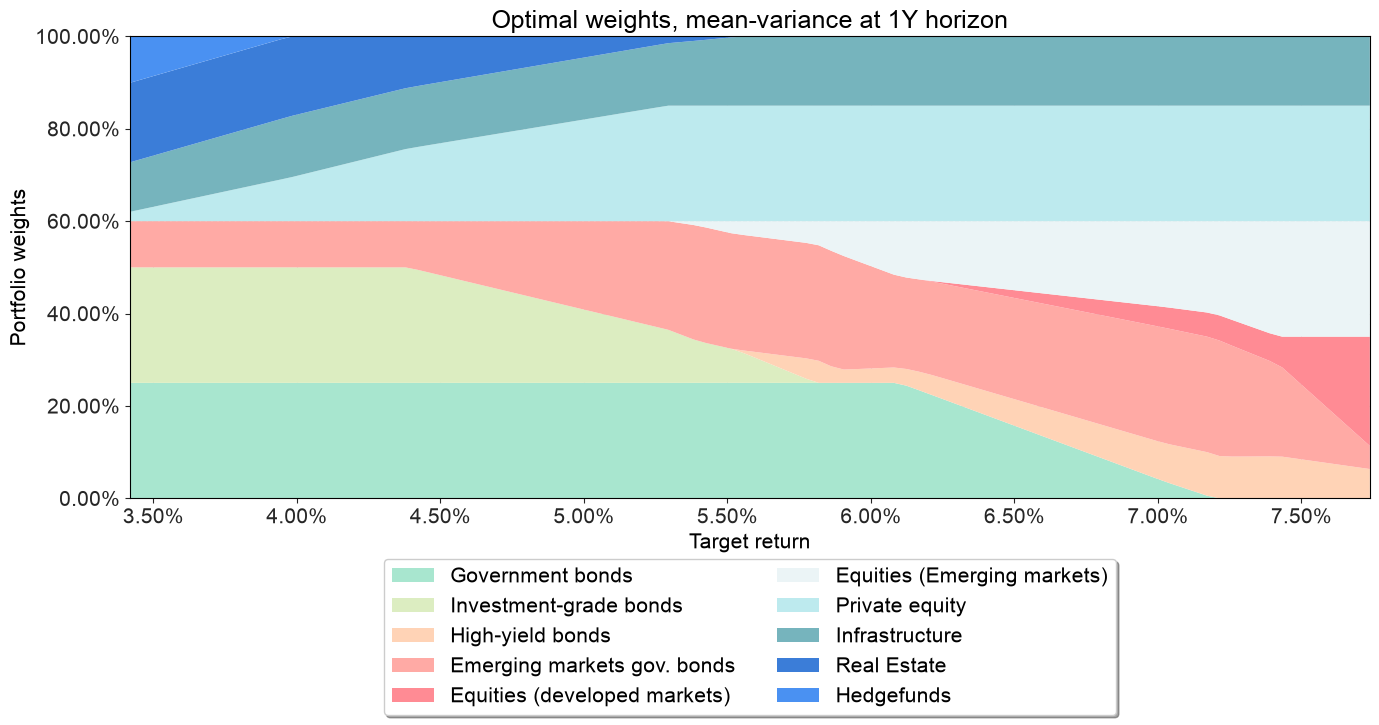

In [44]:
"""
Plot portfolio along the efficient frontier
"""

fig, ax = plt.subplots(figsize=(16, 6))

ax.stackplot(return_targets, optimal_portfolios_w_max_alloc.T,
             labels=asset_names);
ax.set_xlabel("Target return")
ax.set_ylabel("Portfolio weights")
ax.set_title("Optimal weights, mean-variance at 1Y horizon")
ticks = mtick.PercentFormatter(1)
ax.yaxis.set_major_formatter(ticks)
ax.xaxis.set_major_formatter(ticks)
ax.legend(loc='center', bbox_to_anchor=(0.5, -0.3),
          fancybox=True, shadow=True, ncol=2);

In [45]:
"""
Calculate port. expected return along efficient frontier
"""

eff_port_exp_return_w_max_alloc= np.apply_along_axis(rm.calculate_portfolio_mean,
                                          1, optimal_portfolios_w_max_alloc, mu_l)

"""
Calculate port. std
"""

eff_port_std_w_max_alloc = np.apply_along_axis(rm.calculate_portfolio_std,
                                   1, optimal_portfolios_w_max_alloc, sigma_l)

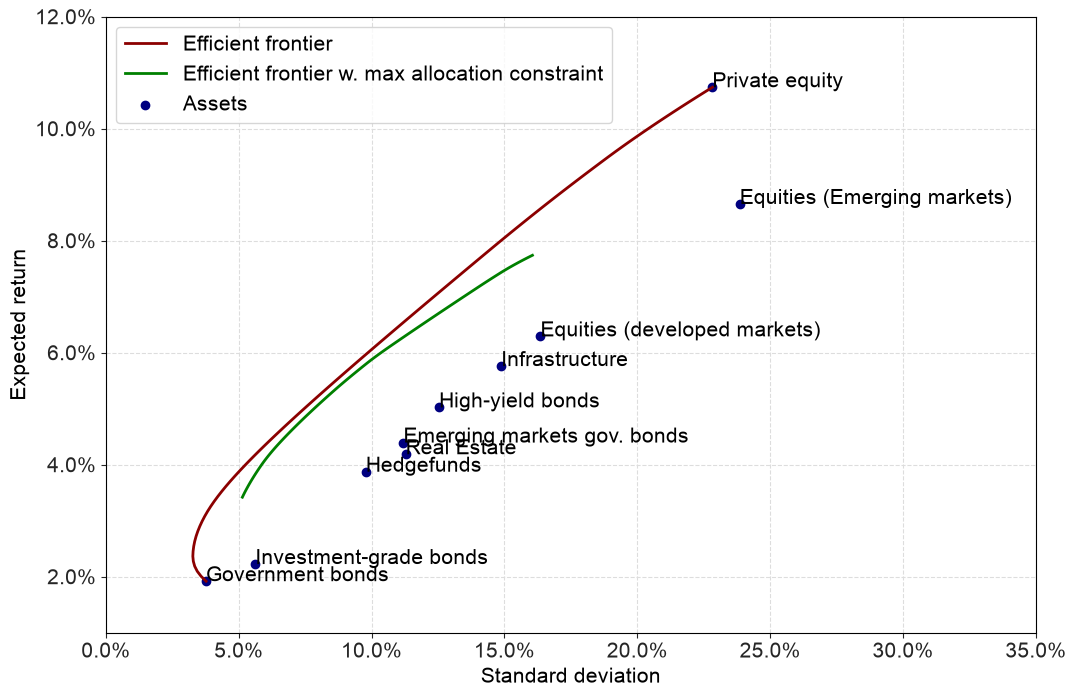

In [46]:
fig, ax = plt.subplots(figsize=(12, 8))

# plot efficient frontier
ax.plot(eff_port_std, eff_port_exp_return, label="Efficient frontier",
        color="darkred")

ax.plot(eff_port_std_w_max_alloc, eff_port_exp_return_w_max_alloc,
        label="Efficient frontier w. max allocation constraint",
        color="green")

# add the different assets
assets_std = np.sqrt(np.diag(sigma_l))
ax.scatter(assets_std, mu_l, color="navy", label="Assets")
for i in range(num_assets):
    ax.annotate(asset_names[i], (assets_std[i], mu_l[i]))

# set correct tick labels, etc.
ticks = mtick.PercentFormatter(1)
ax.yaxis.set_major_formatter(ticks)
ax.xaxis.set_major_formatter(ticks)

ax.set(xlabel="Standard deviation", ylabel="Expected return")

ax.set_xlim([0.0, 0.35])
ax.set_ylim([0.01, 0.12])
ax.legend(loc="upper left");

**Tolkning (Q1):** The log-returns are assumed multivariate Normal, so the asset prices are log-normal. A weighted sum of log-normal variables is NOT log-normal, so the portfolio return has no simple named distribution. What we can do is derive its expected value and variance from the mean and covariance of the linear returns, using the log-normal formulas. This is why we must convert from log-returns to linear returns before mixing assets in a portfolio.

**Tolkning (Q2):** The equal-weighted portfolio has an expected return of about 5.3% and a standard deviation of about 9.7%. Although every asset has the same 10% of the CAPITAL, they contribute very different amounts of RISK: emerging-market equities and private equity together account for about 41% of the total risk, while government bonds contribute essentially nothing (they even slightly hedge the rest, because of their negative correlations with equities). Again: capital weight is not risk weight.

**Tolkning (Q3-Q4):** For every return target the solver finds the least risky mix, and together they form the efficient frontier. At low targets the portfolio is mostly safe government bonds, and as the target rises the money moves into private equity, until the highest possible return is reached by holding only private equity (the highest-return asset). The optimal portfolios are dominated by just a few assets: several asset classes (for example both equity classes) get zero weight, because other assets deliver more return for similar or lower risk. The single assets lie to the right of or below the frontier, which shows the benefit of diversification.

**Tolkning (Q5):** The 25% cap per asset and the 40% cap on alternatives force a more diversified portfolio (no more 100% in one asset), and the constrained frontier lies to the right of the unconstrained one: for the same return we have to accept more risk. The cost grows with the return target (for example about 2 percentage points more risk at a 7.7% target), and the highest returns become unreachable, since the best possible return falls from about 10.7% to about 7.8%.

## Problem 6: Hedging a cash flow

__Question 1__

Download the US Treasury nominal zero coupon yields using e.g. `dal.fred_yield_data.get_nominal_yield_data`.

Visualize the data using a scatter plot for 2nd September 2025.

__Question 2__

For simplicity, assume that we have 8 bullet bonds available with respectively 1, 3, 5, 7, 10, 13, 15, 20 years to maturity. All have bonds have a coupon of 4\% with annual payments and face value of 100 (e.g the 3 year bond has a payment of 4 one and two year from now, and a payment of 104 three years from now).

Calculate the present value (price) of the bonds cash flow.

__Question 3__

Create a cash flow matrix (number of bonds x number of cash flow time points) using all the bonds such that the rows contains the cash flows for each bond.

__Question 4__

Asssume a liability cash flow of


|  Time  |            Cash flow |
|---:|-------------:|
|  1 | 1000000   |
|  2 | 1100000 |
|  3 | 1200000 |
|  4 | 1300000 |
|  5 | 1400000 |
|  6 | 1500000 |
|  7 | 1400000 |
|  8 | 1300000 |
|  9 | 1200000 |
| 10 | 1100000 |
| 11 | 1000000  |
| 12 | 900000       |
| 13 | 800000       |
| 14 | 700000       |
| 15 | 600000       |
| 16 | 500000       |
| 17 | 400000       |
| 18 | 300000       |
| 19 | 200000       |
| 20 | 100000       |

Plot the liability cash flow with a bar plot.

__Question 5__

It is possible to solve the simple cash flow matching problem using linear programming [[W]](https://en.wikipedia.org/wiki/Cashflow_matching). Suppose that we have a choice of $j=1,...,n $ bonds with which to receive cash flows over $t=1,...,T$ time periods in order to cover liabilities $L_{1},...,L_{T}$ for each time period.  The $j$th bond in time period $t$ is assumed to have known cash flows $C_{jt}$ and initial price $p_{j}$. It possible to buy $x_{j}$ bonds and to run a surplus $s_{t}$ in a given time period, both of which must be non-negative, and leads to the set of constraints

$$\begin{align}
\sum_{j=1}^{n}C_{j1}x_{j} - s_{1} &= L_{1} \\
\sum_{j=1}^{n}C_{jt}x_{j} + s_{t-1} - s_{t} &= L_{t}, \quad t = 2,...,T
\end{align}
$$

Our goal is to minimize the initial cost of purchasing bonds to meet the liabilities in each time period, given by $\mathbf{p}^{\top} \mathbf{x}$. Together, these requirements give rise to the associated linear programming problem

$$
\min \mathbf{p}^\top \mathbf{x}
$$

subject to the constraints

$$
\mathbf{C}^\top \mathbf{x} + \mathbf{R} \mathbf{s} \geq \mathbf{L}
$$

and

$$
\mathbf{x}, \mathbf{s} \geq 0
$$

where $\mathbf{C}$ is the $n \times T$ matrix and $\mathbf{R}$ is a $T \times T$ matrix with $R_{t,t}=-1$ and $R_{t+1, t}=1$

Define and solve the cash flow matching problem using either `cvxopt` or `cvxpy`.

__Question 6__

Compare the cummulative liability cash flow with the cummulative hedge cash flow using a bar plot.

### Solution

__Question 1__


In [47]:
# Get zero yields
df_zero_yields = get_nominal_yield_data(output_type="zero_yields")
zero_yields = df_zero_yields.loc['2025-09-02', :].values

# define tenors / time to maturity
tenors = np.array([float(text[-2:])  for text in df_zero_yields.columns])

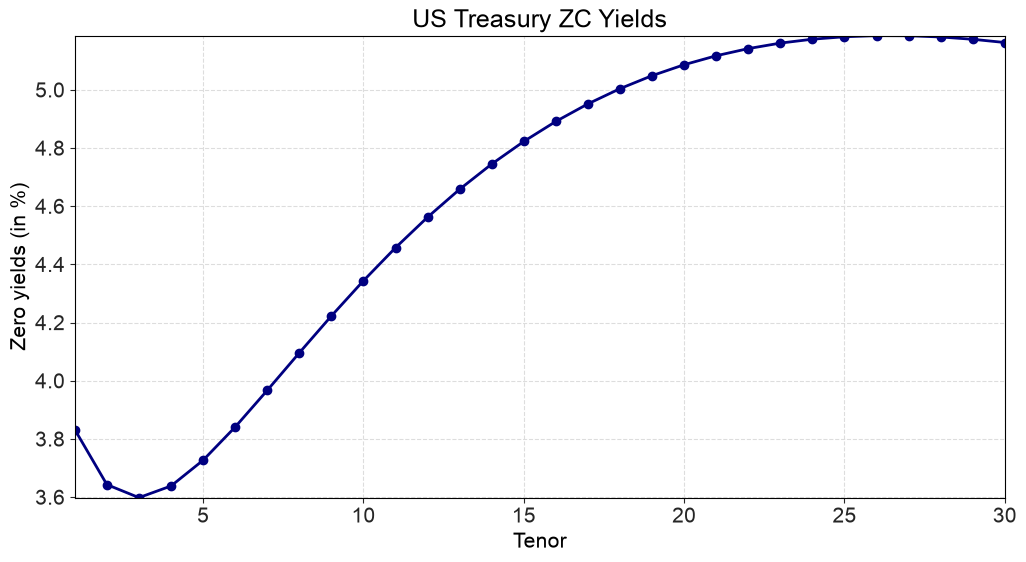

In [48]:
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(tenors, zero_yields, color="navy", linestyle="-", marker="o")
ax.set(xlabel="Tenor", ylabel="Zero yields (in %)", title="US Treasury ZC Yields");

__Question 2__

In [49]:
from scipy.interpolate import splev, splrep
from functools import reduce

# define zero coupon curve - divid by 100 to get yields to decimal number
zero_curve_spline = splrep(tenors, zero_yields / 100)

In [50]:
"""
One possibility would also just be to type the cash flow matrix manually...
"""

coupon = 0.04

# define maturities
maturities = np.array([1, 3, 5, 7, 10, 13, 15, 20])

# prices
prices = list()
# cash flow time points
term_info = list()
# cash flows
flow_info = list()

# loop over all maturities
for maturity in maturities:

    # create cash flow time points
    terms = np.arange(1.0, maturity + 1.0, 1.0)
    # create cash flow
    flows = np.ones_like(terms) * 100 * 0.04
    flows[-1] += 100

    # store info
    term_info.append(terms)
    flow_info.append(flows)

    # calculate price
    prices.append(np.sum(flows * np.exp(-terms * splev(terms, zero_curve_spline))))

In [51]:
flow_info

[array([104.]),
 array([  4.,   4., 104.]),
 array([  4.,   4.,   4.,   4., 104.]),
 array([  4.,   4.,   4.,   4.,   4.,   4., 104.]),
 array([  4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4., 104.]),
 array([  4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,
          4., 104.]),
 array([  4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,
          4.,   4.,   4., 104.]),
 array([  4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,   4.,
          4.,   4.,   4.,   4.,   4.,   4.,   4.,   4., 104.])]

In [52]:
df_res = pd.DataFrame(index=maturities, data=prices, columns=["Price"])
df_res.index.name="Maturity"
df_res

,Price
Maturity,
1,100.090212
3,100.926866
5,100.937054
7,99.898036
10,97.120041
13,93.875812
15,91.809504
20,87.613449


__Question 3__

In [53]:
# Get union of all cash flow time points
all_terms = reduce(np.union1d, term_info)

# define the shape of the cash flow matrix
cash_flow_matrix = np.zeros((maturities.shape[0] , all_terms.shape[0]))

# create the cash flow matrix
idx = 0
for terms, flows in zip(term_info, flow_info):

    indicator = np.isin(all_terms, terms)
    cash_flow_matrix[idx, indicator] = flows

    idx += 1

In [54]:
pd.DataFrame(index=maturities, data=cash_flow_matrix, columns=all_terms)

,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
1,104.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,4.0,104.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,4.0,4.0,4.0,104.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,4.0,4.0,4.0,4.0,4.0,4.0,104.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,104.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,104.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,104.0,0.0,0.0,0.0,0.0,0.0
20,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,104.0


__Question 4__

In [55]:
liab_time_points = np.arange(1.0, 21.0, 1.0)
liab_cash_flows = np.array([1.0, 1.1, 1.2, 1.3, 1.4, 1.5,
                            1.4, 1.3, 1.2, 1.1, 1.0, 0.9,
                            0.8, 0.7, 0.6, 0.5, 0.4, 0.3,
                            0.2, 0.1]) * 1e6

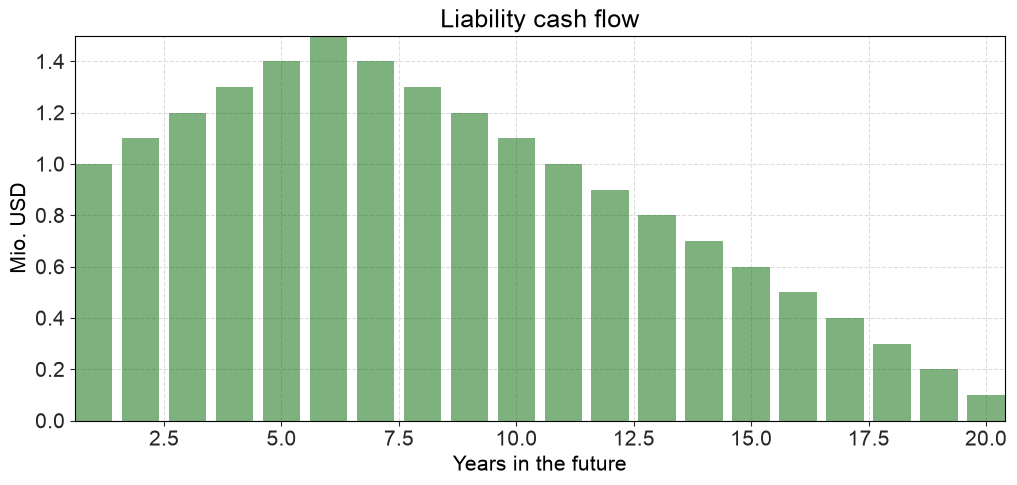

In [56]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(liab_time_points, liab_cash_flows / 1e6, color="darkgreen", alpha=0.5);

ax.set_title("Liability cash flow")
ax.set_xlabel("Years in the future")
ax.set_ylabel("Mio. USD");

__Question 5__

In [57]:
num_time_points = len(liab_time_points)
num_bonds = len(maturities)

r_mat  = -np.eye(num_time_points)
r_mat[range(num_time_points - 1), range(1, num_time_points)] =  1

In [58]:
x = cp.Variable(num_bonds)
s = cp.Variable(num_time_points)

c_mat = cash_flow_matrix
b_vec = liab_cash_flows
p_vec = np.array(prices)

problem = cp.Problem(cp.Minimize(p_vec @ x),
                     [c_mat.T @ x + r_mat.T @ s >= b_vec, x >= 0, s >= 0])

problem.solve()

x.value

array([10545.75596962, 15591.23558434, 21057.17187904, 30814.3349481 ,
       25050.9873517 , 12884.04641698, 19045.85800225,   961.53840327])

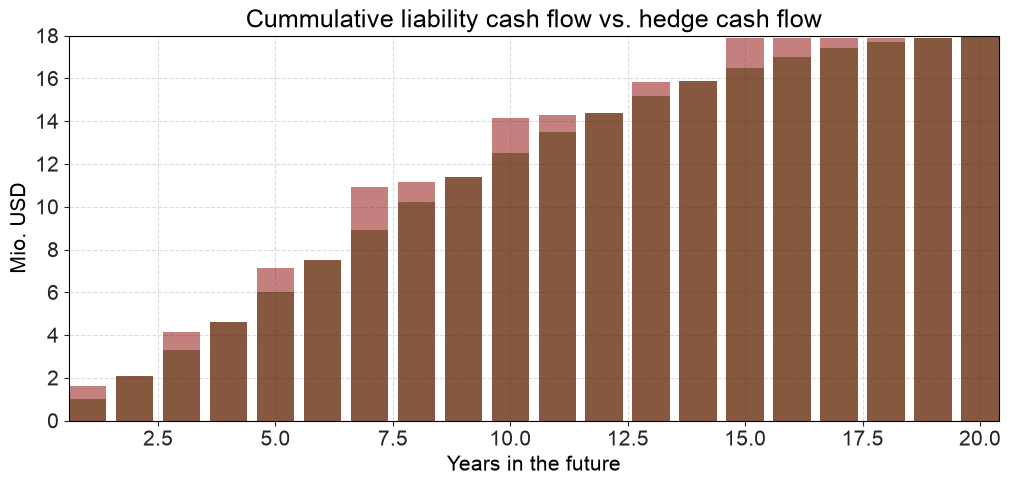

In [59]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(liab_time_points, liab_cash_flows.cumsum() / 1e6, color="darkgreen", alpha=0.5);
ax.bar(liab_time_points, (c_mat.T @ x.value).cumsum() / 1e6, color="darkred", alpha=0.5);

ax.set_title("Cummulative liability cash flow vs. hedge cash flow")
ax.set_xlabel("Years in the future")
ax.set_ylabel("Mio. USD");

**Tolkning (Q1):** A zero-coupon yield curve shows, for each maturity (in years), the interest rate for borrowing or lending over exactly that period. It is the "price of time" that we use to discount every future cash flow back to today. The plot shows this curve for one specific day (2 September 2025).

**Tolkning (Q2-Q3):** The price of a bond is the sum of all its future payments, each discounted back to today using the yield curve (an interpolated spline gives us the rate for any maturity). The cash flow matrix simply lists, for each of the 8 bonds, what it pays in each of the 20 years. This is the "shopping catalogue" from which we will build the hedge.

**Tolkning (Q4):** The liabilities are what we must pay out each year: they rise to a peak of 1.5 million in year 6 and then fade gradually to 0.1 million in year 20 (18 million in total, undiscounted). The bar plot shows this hump-shaped payment schedule that our bond portfolio has to cover.

**Tolkning (Q5-Q6):** We let a linear program decide how many of each bond to buy so that every year's payment is covered, at the lowest possible purchase price. Money left over in a year can be carried to the next year (the surplus variable). The final plot compares cumulative liabilities with cumulative hedge cash flows: the red bars never fall below the green ones, which shows that the liabilities are covered at every point in time. In the illustration the hedge costs slightly more than the present value of the liabilities, because only 8 bond maturities exist (their lump sums cannot match the 20 payments perfectly) and any leftover cash earns nothing while it waits.

**Kort resumé af de 6 problemer**

Problem 1: Second order conditions. Hessian-matricens egenværdier afgør, om et fladt punkt er maksimum, minimum eller sadelpunkt.

Problem 2: Minimizing distance. Første bibetingelse: korteste tur via planetens overflade, hvor "sfære = 1" skrives som en 'eq'-betingelse.

Problem 3: Portfolio optimization with constraints. Efficient frontier opbygget ved at løse minimum-varians for mange afkastmål; et loft på 30 % pr. aktiv giver mere diversifikation og højere risiko.

Problem 4: Minimizing CVaR. Samme opskrift, men med CVaR som mål i stedet for varians. Den er beregnet direkte fra historien, så løseren skal have strammere indstillinger.

Problem 5: Mean-variance med 10 aktivklasser. Log-afkast omregnes til lineære afkast, risikobidrag viser hvor risikoen sidder, og frontieren beregnes med cvxpy med og uden lofter (25 % pr. aktiv, 40 % til alternativer).

Problem 6: Hedging a cash flow. Cash-flow-matching som lineært program: køb obligationer så billigt som muligt, så alle fremtidige forpligtelser dækkes.

🎯 De 3 vigtigste ting at huske til eksamen fra Week 5
Classify with the Hessian: The first order condition (gradient = 0) finds the candidates, and the eigenvalues of the Hessian decide the type (all negative = maximum, all positive = minimum, mixed = saddle point). A global extremum on a bounded set also requires checking the boundary.
Constraint format matters: In SciPy an equality must be written as "= 0" and an inequality as "≥ 0" (flip any "≤"). Convex problems (LP, QP, SOCP) are easiest in cvxpy. Always verify the solution by recomputing the constrained quantity, and watch solver tolerances (ftol).
The efficient frontier is the same minimum-risk problem solved for many return targets (using linear, not log, returns). Every extra constraint raises risk or shrinks the reachable returns, and capital weight is not risk weight.

Punkterne er gemt til dit eksamens-notat, ligesom for Week 2 til 4.